In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/forest-cover-type-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'forest-cover-type-dataset' dataset.
Path to dataset files: /kaggle/input/forest-cover-type-dataset


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print("Dataset path:",path)
print("Files:",os.listdir(path))

Dataset path: /kaggle/input/forest-cover-type-dataset
Files: ['covtype.csv']


In [4]:
csv_path = os.path.join(path,"covtype.csv")

df = pd.read_csv(csv_path)
df.shape

(581012, 55)

In [5]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null 

In [7]:
df.isnull().sum()

,0
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,...,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226,...,0.090392,0.077716,0.002773,0.003255,0.000205,0.000513,0.026803,0.023762,0.015060,2.051471
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210,...,0.286743,0.267725,0.052584,0.056957,0.014310,0.022641,0.161508,0.152307,0.121791,1.396504
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


In [10]:
df.nunique().sort_values()

,0
Wilderness_Area3,2
Wilderness_Area4,2
Soil_Type2,2
Soil_Type1,2
Wilderness_Area1,2
Wilderness_Area2,2
Soil_Type12,2
Soil_Type11,2
Soil_Type10,2
Soil_Type9,2


In [11]:
df["Cover_Type"].value_counts().sort_index()

,count
Cover_Type,
1,211840
2,283301
3,35754
4,2747
5,9493
6,17367
7,20510


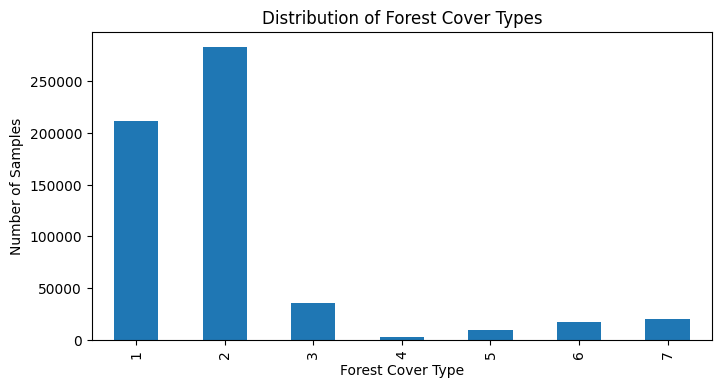

In [12]:
df["Cover_Type"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.xlabel("Forest Cover Type")
plt.ylabel("Number of Samples")
plt.title("Distribution of Forest Cover Types")
plt.show()

In [13]:
X = df.drop('Cover_Type',axis=1)
y = df['Cover_Type']

print("Feature shpe:",X.shape)
print("Target shape",y.shape)

Feature shpe: (581012, 54)
Target shape (581012,)


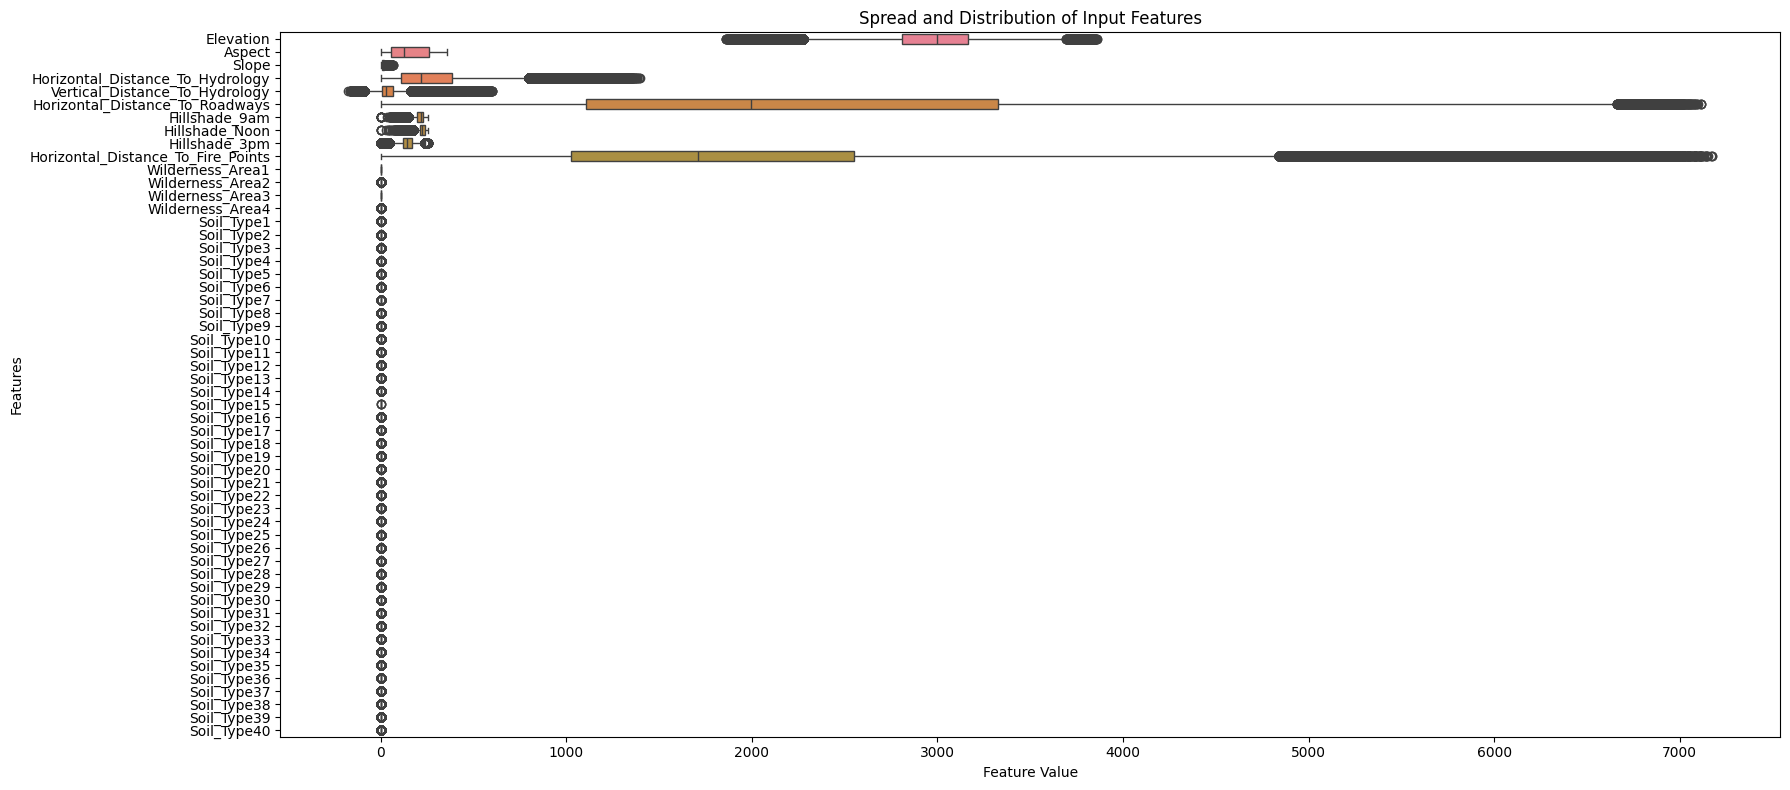

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns


# Plot boxplots for all input features
plt.figure(figsize=(18, 8))
sns.boxplot(data=X, orient="h")

plt.title("Spread and Distribution of Input Features")
plt.xlabel("Feature Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [31]:
 from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Cover_Type"])
y = df["Cover_Type"]

# 70% training, 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split remaining data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (406708, 54) (406708,)
Validation: (87152, 54) (87152,)
Testing: (87152, 54) (87152,)


In [32]:
from sklearn.preprocessing import StandardScaler

# Continuous numerical features
continuous_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

scaler = StandardScaler()

X_train[continuous_cols]=scaler.fit_transform(
    X_train[continuous_cols]
)

X_val[continuous_cols]=scaler.transform(
    X_val[continuous_cols]
)

X_test[continuous_cols]=scaler.transform(
    X_test[continuous_cols]
)








In [33]:
X_test.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
253235,1.290439,0.502331,-0.682334,1.754576,0.815587,0.901050,0.032530,1.299059,0.769388,0.303227,...,0,0,0,0,0,0,0,0,0,0
301775,-1.611918,-0.908938,-0.682334,-0.270103,0.198108,-0.956924,0.480859,-0.117231,-0.327625,-1.170663,...,0,0,0,0,0,0,0,0,0,0
108642,0.112361,0.895343,-1.082982,0.789322,0.489695,1.945518,-0.228996,1.046150,0.873865,-0.110431,...,0,0,0,0,0,0,0,0,0,0
68110,1.015554,-0.632044,-0.548784,-0.138264,-0.127784,0.419876,0.854468,-0.016067,-0.614938,2.141618,...,0,0,0,0,0,0,0,0,1,0
450758,0.230169,1.592045,0.118962,-0.562034,-0.076327,-0.674635,-1.013573,-0.218394,0.795507,-0.494595,...,0,1,0,0,0,0,0,0,0,0


In [34]:
X_val.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
261080,-2.143838,0.993596,0.786709,0.436180,-0.367915,-1.392546,-1.798150,0.995569,1.918640,-0.937745,...,0,0,0,0,0,0,0,0,0,0
381355,0.615722,0.439807,-0.949433,-0.364275,-0.367915,-0.833101,0.144612,1.147314,0.612672,-0.443171,...,0,0,0,0,0,0,0,0,0,0
249325,-2.393733,0.940003,0.519610,-0.868090,-0.933937,-1.185321,-1.499264,1.197896,1.788043,-1.173688,...,0,0,0,0,0,0,0,0,0,0
189619,0.390816,-0.676704,-0.148136,-1.070558,-0.693806,1.003700,0.929189,-0.420721,-0.928371,-1.099578,...,0,0,0,0,0,0,0,0,0,0
53795,-0.180374,-0.551655,-0.415235,-0.985804,-0.590893,0.901050,0.966550,-0.016067,-0.719416,2.347313,...,0,0,0,0,0,0,0,0,0,0


In [35]:
X_train.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40
244336,-0.487388,-1.123308,1.988653,-0.505531,-0.007719,-0.770228,-0.527882,-2.949810,-1.450758,-0.175466,...,0,0,0,0,0,0,0,0,0,0
518278,1.297579,1.600978,0.118962,1.641571,0.506847,-0.939601,-1.013573,-0.268976,0.769388,-0.608785,...,0,0,0,0,0,0,0,0,0,0
151614,-0.490958,1.699230,-0.014587,-0.759793,-0.453676,0.049051,-0.752047,-0.319558,0.508194,-0.035564,...,0,0,0,0,0,0,0,0,0,0
85676,-0.430269,-0.024662,-0.949433,-1.268318,-0.796719,1.058875,0.630303,0.894405,0.038046,1.046599,...,0,0,0,0,0,0,0,0,0,0
419952,0.758519,0.493399,0.920258,-0.166515,0.575456,0.515469,-0.527882,1.551968,1.082820,-0.757006,...,0,0,1,0,0,0,0,0,0,0


In [36]:
X_train.shape

(406708, 54)

In [37]:
y_train_tf = y_train - 1
y_val_tf = y_val - 1
y_test_tf = y_test -1

print("Unique target labels:",sorted(y_train_tf.unique()))

'''We subtract 1 because TensorFlow classification models
 commonly use class indices starting at 0'''

Unique target labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


'We subtract 1 because TensorFlow classification models\n commonly use class indices starting at 0'

In [38]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(7, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop =EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train_tf,
    validation_data=(X_val,y_val_tf),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.7576 - loss: 0.5742 - val_accuracy: 0.7974 - val_loss: 0.4763
Epoch 2/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8105 - loss: 0.4454 - val_accuracy: 0.8245 - val_loss: 0.4249
Epoch 3/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8320 - loss: 0.4012 - val_accuracy: 0.8412 - val_loss: 0.3876
Epoch 4/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8453 - loss: 0.3734 - val_accuracy: 0.8511 - val_loss: 0.3662
Epoch 5/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8534 - loss: 0.3538 - val_accuracy: 0.8520 - val_loss: 0.3550
Epoch 6/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8601 - loss: 0.3391 - val_accuracy: 0.8558 - val_loss: 0.3472
Epoch 7/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8648 - loss: 0.3261 - val_accuracy: 0.8644 - val_loss: 0.3318
Epoch 8/100
1589/1589 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8692 - lo

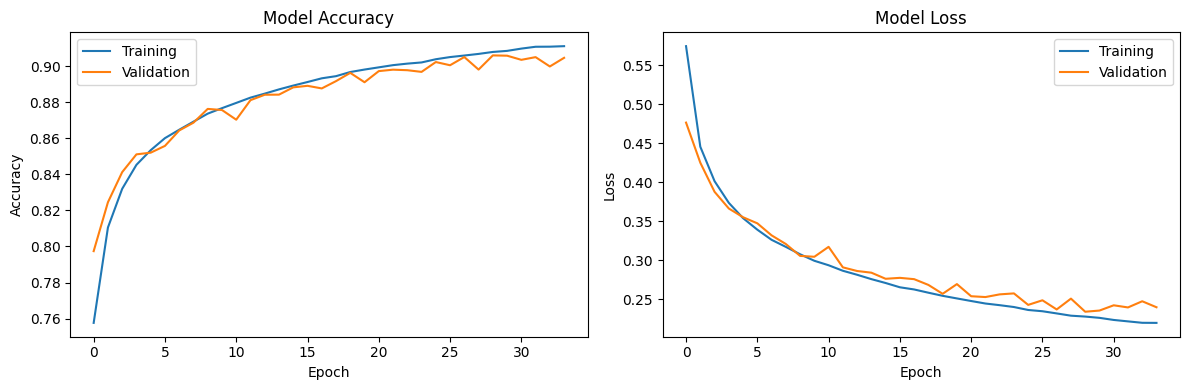

In [40]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Test Loss: 0.2347
Test Accuracy: 90.6657%

Classification Report:
              precision    recall  f1-score   support

Cover Type 1     0.9104    0.8942    0.9022     31776
Cover Type 2     0.9104    0.9301    0.9202     42496
Cover Type 3     0.9228    0.8851    0.9036      5363
Cover Type 4     0.8070    0.7816    0.7941       412
Cover Type 5     0.8426    0.6580    0.7390      1424
Cover Type 6     0.8212    0.8392    0.8301      2605
Cover Type 7     0.8988    0.9379    0.9179      3076

    accuracy                         0.9067     87152
   macro avg     0.8733    0.8466    0.8581     87152
weighted avg     0.9065    0.9067    0.9063     87152



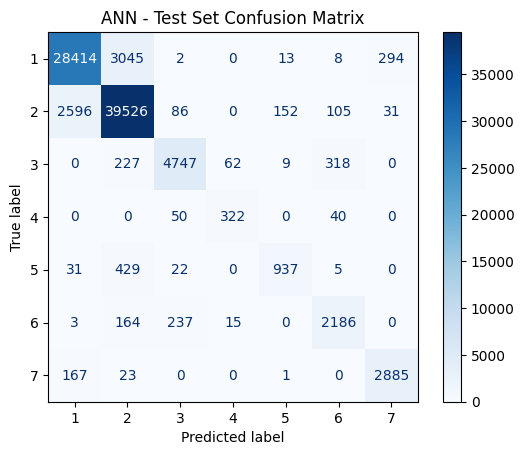

In [41]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Evaluate on the untouched test set
test_loss, test_accuracy = model.evaluate(
    X_test, y_test_tf, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# Generate predictions
test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

# Detailed metrics for all seven classes
print("\nClassification Report:")
print(classification_report(
    y_test_tf,
    y_pred,
    labels=np.arange(7),
    target_names=[f"Cover Type {i}" for i in range(1, 8)],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test_tf, y_pred, labels=np.arange(7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(1, 8)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ANN - Test Set Confusion Matrix")
plt.show()


In [42]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# Train on the original training split.
# Scaling is not required for Random Forest.
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_train_time = time.time() - start_time

# Evaluate on the same untouched test split
rf_pred = rf_model.predict(X_test)

print(f"Training time: {rf_train_time:.2f} seconds")
print(f"Test Accuracy: {accuracy_score(y_test, rf_pred):.4%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    digits=4,
    zero_division=0
))


Training time: 164.42 seconds
Test Accuracy: 95.1418%

Classification Report:
              precision    recall  f1-score   support

           1     0.9612    0.9399    0.9504     31776
           2     0.9465    0.9705    0.9584     42496
           3     0.9380    0.9569    0.9474      5363
           4     0.8903    0.8471    0.8682       412
           5     0.9394    0.7514    0.8350      1424
           6     0.9295    0.8952    0.9120      2605
           7     0.9770    0.9509    0.9638      3076

    accuracy                         0.9514     87152
   macro avg     0.9403    0.9017    0.9193     87152
weighted avg     0.9515    0.9514    0.9512     87152



Top 15 important features:
Elevation                             0.241443
Horizontal_Distance_To_Roadways       0.116547
Horizontal_Distance_To_Fire_Points    0.110526
Horizontal_Distance_To_Hydrology      0.060882
Vertical_Distance_To_Hydrology        0.057957
Aspect                                0.048126
Hillshade_Noon                        0.043308
Hillshade_9am                         0.041792
Hillshade_3pm                         0.041520
Slope                                 0.033276
Wilderness_Area4                      0.030532
Soil_Type22                           0.015823
Soil_Type10                           0.012957
Soil_Type4                            0.012550
Wilderness_Area3                      0.011215
dtype: float64


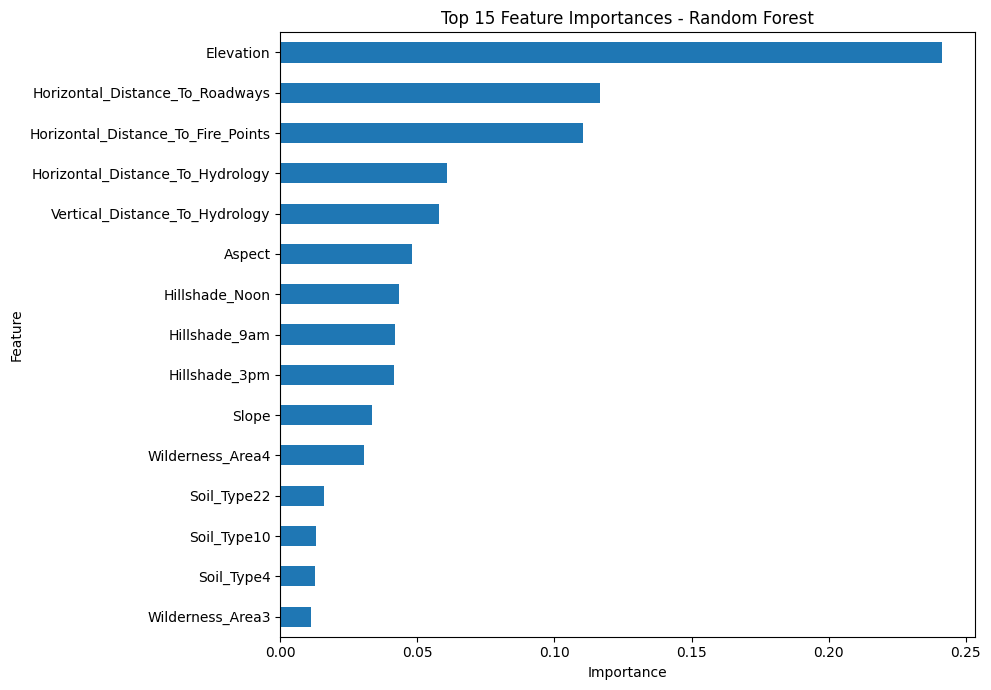

In [43]:

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 15 important features:")
print(feature_importance.head(15))

plt.figure(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [44]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

# Select top 15 features from the fitted baseline model
top15_features = feature_importance.head(15).index.tolist()

print("Selected features:", len(top15_features))
print(top15_features)

# Train using only the selected features
rf_top15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_top15.fit(
    X_train[top15_features],
    y_train
)

top15_train_time = time.time() - start_time

# Evaluate on validation data, not test data
val_pred_top15 = rf_top15.predict(
    X_val[top15_features]
)

print(f"\nTraining time: {top15_train_time:.2f} seconds")
print(
    "Validation accuracy:",
    f"{accuracy_score(y_val, val_pred_top15):.4%}"
)
print(
    "Validation macro F1:",
    f"{f1_score(y_val, val_pred_top15, average='macro'):.4f}"
)


Selected features: 15
['Elevation', 'Horizontal_Distance_To_Roadways', 'Horizontal_Distance_To_Fire_Points', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Aspect', 'Hillshade_Noon', 'Hillshade_9am', 'Hillshade_3pm', 'Slope', 'Wilderness_Area4', 'Soil_Type22', 'Soil_Type10', 'Soil_Type4', 'Wilderness_Area3']

Training time: 154.18 seconds
Validation accuracy: 94.4625%
Validation macro F1: 0.9117


In [45]:
!git config --global user.name "sawan-kush"
!git config --global user.email "sawankushwah0902@gmail.com"